### Name: Runal Gavade
### Roll No: 62
### Assignment-6

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


In [13]:
df = pd.read_csv("uber.csv")

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

First five rows:
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647             

In [14]:
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")

df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)

df = df.dropna()
df = df.drop_duplicates()

df = df[
    (df["fare_amount"] > 0) &
    (df["fare_amount"] <= 100) &
    (df["passenger_count"].between(1, 6)) &
    (df["pickup_latitude"].between(40, 42)) &
    (df["dropoff_latitude"].between(40, 42)) &
    (df["pickup_longitude"].between(-75.5, -72.5)) &
    (df["dropoff_longitude"].between(-75.5, -72.5))
].copy()

print("Shape after preprocessing:", df.shape)

Shape after preprocessing: (195031, 7)


Lower outlier limit: -3.75
Upper outlier limit: 22.25
Number of fare outliers: 16636


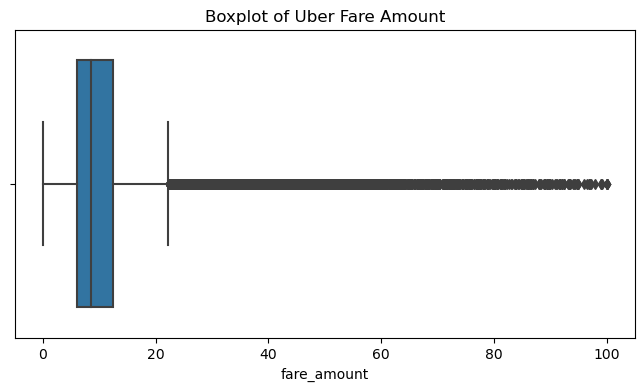

In [15]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["fare_amount"] < lower_limit) |
    (df["fare_amount"] > upper_limit)
]

print("Lower outlier limit:", round(lower_limit, 2))
print("Upper outlier limit:", round(upper_limit, 2))
print("Number of fare outliers:", len(outliers))

plt.figure(figsize=(8, 4))
sns.boxplot(x=df["fare_amount"])
plt.title("Boxplot of Uber Fare Amount")
plt.show()

In [16]:
def haversine_distance(lat1, lon1, lat2, lon2):
    earth_radius = 6371

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 2 * earth_radius * np.arcsin(
        np.sqrt(np.clip(a, 0, 1))
    )


df["distance_km"] = haversine_distance(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"]
)

df = df[
    (df["distance_km"] > 0) &
    (df["distance_km"] <= 100)
].copy()

print("Shape after distance calculation:", df.shape)

Shape after distance calculation: (192994, 8)


In [18]:
df["pickup_hour"] = df["pickup_datetime"].dt.hour
df["pickup_day"] = df["pickup_datetime"].dt.day
df["pickup_month"] = df["pickup_datetime"].dt.month
df["pickup_year"] = df["pickup_datetime"].dt.year

print("Final dataset shape:", df.shape)
print(df.head())

Final dataset shape: (192994, 12)
   fare_amount           pickup_datetime  pickup_longitude  pickup_latitude  \
0          7.5 2015-05-07 19:52:06+00:00        -73.999817        40.738354   
1          7.7 2009-07-17 20:04:56+00:00        -73.994355        40.728225   
2         12.9 2009-08-24 21:45:00+00:00        -74.005043        40.740770   
3          5.3 2009-06-26 08:22:21+00:00        -73.976124        40.790844   
4         16.0 2014-08-28 17:47:00+00:00        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  distance_km  \
0         -73.999512         40.723217                1     1.683323   
1         -73.994710         40.750325                1     2.457590   
2         -73.962565         40.772647                1     5.036377   
3         -73.965316         40.803349                3     1.661683   
4         -73.973082         40.761247                5     4.475450   

   pickup_hour  pickup_day  pickup_month  pickup_year  
0 

Correlation Matrix:
                 fare_amount  distance_km  passenger_count  pickup_hour  \
fare_amount             1.00         0.86             0.01        -0.02   
distance_km             0.86         1.00             0.01        -0.03   
passenger_count         0.01         0.01             1.00         0.01   
pickup_hour            -0.02        -0.03             0.01         1.00   
pickup_day              0.00         0.00             0.00         0.01   
pickup_month            0.02         0.01             0.01        -0.00   
pickup_year             0.12         0.02             0.01         0.00   

                 pickup_day  pickup_month  pickup_year  
fare_amount            0.00          0.02         0.12  
distance_km            0.00          0.01         0.02  
passenger_count        0.00          0.01         0.01  
pickup_hour            0.01         -0.00         0.00  
pickup_day             1.00         -0.02        -0.01  
pickup_month          -0.02          

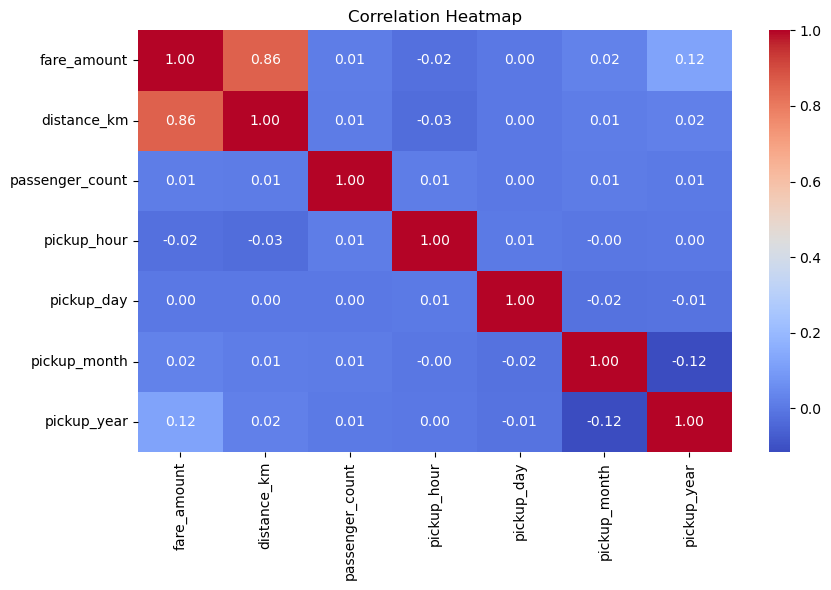

In [19]:
features = [
    "fare_amount",
    "distance_km",
    "passenger_count",
    "pickup_hour",
    "pickup_day",
    "pickup_month",
    "pickup_year"
]

correlation = df[features].corr()

print("Correlation Matrix:")
print(correlation.round(2))

plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [20]:
X = df[
    [
        "distance_km",
        "passenger_count",
        "pickup_hour",
        "pickup_day",
        "pickup_month",
        "pickup_year"
    ]
]

y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 154395
Testing rows: 38599


In [21]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [22]:
forest_model = RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=1
)

forest_model.fit(X_train, y_train)

forest_predictions = forest_model.predict(X_test)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [23]:
def evaluate_model(name, actual, predicted):
    r2 = r2_score(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)

    print("\n" + name)
    print("R2 Score:", round(r2, 4))
    print("RMSE:", round(rmse, 4))
    print("MAE:", round(mae, 4))

    return [r2, rmse, mae]


linear_results = evaluate_model(
    "Linear Regression",
    y_test,
    linear_predictions
)

forest_results = evaluate_model(
    "Random Forest Regression",
    y_test,
    forest_predictions
)


Linear Regression
R2 Score: 0.7824
RMSE: 4.3368
MAE: 2.2833

Random Forest Regression
R2 Score: 0.827
RMSE: 3.8672
MAE: 2.0458


Model Comparison:
                   R2 Score    RMSE     MAE
Linear Regression    0.7824  4.3368  2.2833
Random Forest        0.8270  3.8672  2.0458


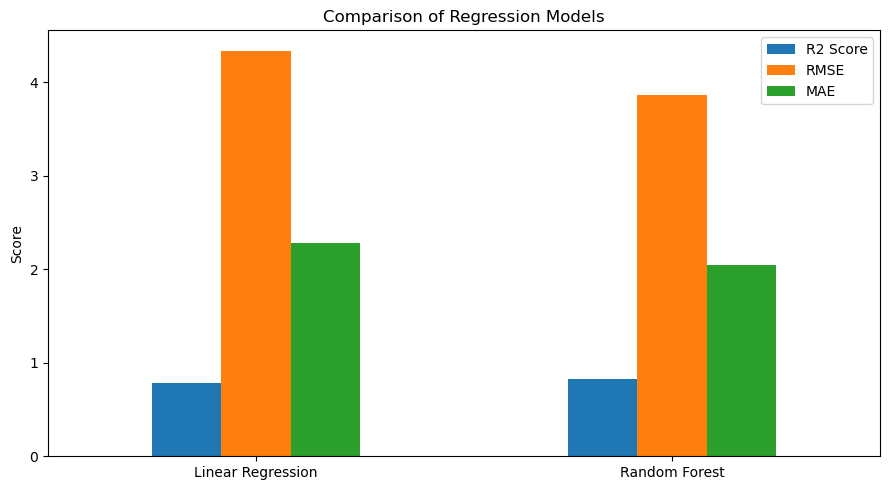

In [24]:
comparison = pd.DataFrame(
    [linear_results, forest_results],
    columns=["R2 Score", "RMSE", "MAE"],
    index=["Linear Regression", "Random Forest"]
)

print("Model Comparison:")
print(comparison.round(4))

comparison.plot(kind="bar", figsize=(9, 5))
plt.title("Comparison of Regression Models")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [25]:
distance = float(input("Enter ride distance in km: "))
passengers = int(input("Enter passenger count: "))
hour = int(input("Enter pickup hour (0-23): "))
day = int(input("Enter pickup day (1-31): "))
month = int(input("Enter pickup month (1-12): "))
year = int(input("Enter pickup year: "))

if (
    distance <= 0 or
    passengers < 1 or
    not 0 <= hour <= 23 or
    not 1 <= day <= 31 or
    not 1 <= month <= 12
):
    print("Please enter valid ride details.")

else:
    new_ride = pd.DataFrame([{
        "distance_km": distance,
        "passenger_count": passengers,
        "pickup_hour": hour,
        "pickup_day": day,
        "pickup_month": month,
        "pickup_year": year
    }])

    prediction = forest_model.predict(new_ride)[0]

    print(
        "\nPredicted Uber fare (Random Forest):",
        round(max(0, prediction), 2)
    )

Enter ride distance in km: 5
Enter passenger count: 2
Enter pickup hour (0-23): 14
Enter pickup day (1-31): 15
Enter pickup month (1-12): 6
Enter pickup year: 2015

Predicted Uber fare (Random Forest): 18.5
